In [2]:
# Загрузка двух датасетов
import kagglehub
import os
import pandas as pd
import numpy as np

# --- Датасет А: High Dimensional Datascape (537 признаков) ---
hd_path = kagglehub.dataset_download("krishd123/high-dimensional-datascape")
hd_file = [f for f in os.listdir(hd_path) if f.endswith('.csv')][0]
hd = pd.read_csv(os.path.join(hd_path, hd_file))

print("=" * 60)
print(f"Датасет А (High Dim): {hd.shape}")
print(f"Первые 5 столбцов: {hd.columns[:5].tolist()}")
print(f"Последние 3 столбца: {hd.columns[-3:].tolist()}")
print(f"\nПервые 2 строки (первые 6 столбцов):")
print(hd.iloc[:2, :6])

# --- Датасет Б: Used Car Prices (регрессия) ---
car_path = kagglehub.dataset_download("krishnaharish1/used-car-prices-synthetic-benchmark")
car_file = [f for f in os.listdir(car_path) if f.endswith('.csv')][0]
car = pd.read_csv(os.path.join(car_path, car_file))

print("\n" + "=" * 60)
print(f"Датасет Б (Used Car): {car.shape}")
print(f"Столбцы: {car.columns.tolist()}")
print(f"\nПервые 2 строки:")
print(car.head(2))

Датасет А (High Dim): (230, 537)
Первые 5 столбцов: ['Unnamed: 0', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']
Последние 3 столбца: ['Unnamed: 534', 'Unnamed: 535', 'Label']

Первые 2 строки (первые 6 столбцов):
   Unnamed: 0  Unnamed: 1  Unnamed: 2  Unnamed: 3  Unnamed: 4  Unnamed: 5
0   -0.000133    0.000262    0.001099    0.001834    0.002109    0.002223
1   -0.000842   -0.001011   -0.001071   -0.000944   -0.000794   -0.000610


100%|██████████| 292k/292k [00:00<00:00, 853kB/s]

Extracting files...

Датасет Б (Used Car): (25000, 10)
Столбцы: ['car_id', 'brand', 'model_year', 'mileage_km', 'fuel_type', 'engine_size_l', 'transmission', 'num_previous_owners', 'accident_history', 'price_usd']

Первые 2 строки:
    car_id  brand  model_year  mileage_km fuel_type  engine_size_l  \
0  C200000    Kia        2023       45300    Petrol            3.2   
1  C200001  Honda        2017      140800    Petrol            2.3   

  transmission  num_previous_owners  accident_history  price_usd  
0       Manual                    1                 0      18100  
1    Automatic                    1                 1       8700  


In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# ============ Датасет А (High Dim) ============
# последняя колонка — метка, остальные — признаки
label_col_hd = hd.columns[-1]
print(f"Метка датасета А: '{label_col_hd}', уникальных значений: {hd[label_col_hd].nunique()}")

X_hd = hd.drop(columns=[label_col_hd])
y_hd = hd[label_col_hd]

print(f"Признаки: {X_hd.shape}, метка: {y_hd.value_counts().to_dict()}")

# Заполняем пропуски (если есть) медианой + масштабируем
imputer_hd = SimpleImputer(strategy='median')
scaler_hd = StandardScaler()
X_hd_scaled = scaler_hd.fit_transform(imputer_hd.fit_transform(X_hd))

print(f"После масштабирования: {X_hd_scaled.shape}, "
      f"среднее ~ {X_hd_scaled.mean():.4f}, std ~ {X_hd_scaled.std():.4f}")

# ============ Датасет Б (Used Car) ============
# Целевая — price_usd, остальные — признаки
TARGET_CAR = 'price_usd'
print(f"\nЦелевая датасета Б: '{TARGET_CAR}'")

X_car = car.drop(columns=[TARGET_CAR])
y_car = car[TARGET_CAR]

print(f"Признаки: {X_car.shape}")
print(f"Числовых: {X_car.select_dtypes(include=['int64', 'float64']).shape[1]}")
print(f"Категориальных: {X_car.select_dtypes(include=['object']).shape[1]}")
print(f"\nЦелевая: min={y_car.min():.0f}, max={y_car.max():.0f}, mean={y_car.mean():.0f}")

Метка датасета А: 'Label', уникальных значений: 2
Признаки: (230, 536), метка: {0: 115, 1: 115}
После масштабирования: (230, 536), среднее ~ -0.0000, std ~ 1.0000

Целевая датасета Б: 'price_usd'
Признаки: (25000, 9)
Числовых: 5
Категориальных: 4

Целевая: min=1500, max=64500, mean=8686


C:\Users\Asus\AppData\Local\Temp\ipykernel_2348\2457191132.py:32: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(f"Категориальных: {X_car.select_dtypes(include=['object']).shape[1]}")


High Dim — для 85% дисперсии: 22 компонент
High Dim — для 95% дисперсии: 31 компонент
Всего компонент: 230


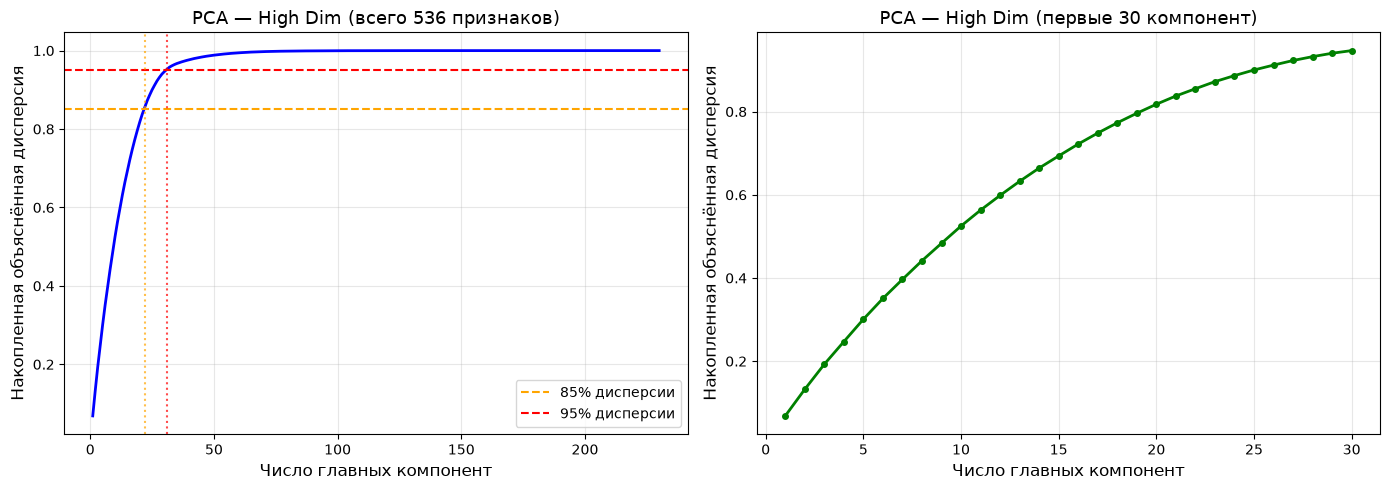

In [4]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# ============ PCA для High Dim ============
pca_hd = PCA(random_state=42)
pca_hd.fit(X_hd_scaled)
cum_var_hd = np.cumsum(pca_hd.explained_variance_ratio_)

# Сколько компонент нужно для 85% и 95%?
n_85_hd = np.argmax(cum_var_hd >= 0.85) + 1
n_95_hd = np.argmax(cum_var_hd >= 0.95) + 1

print(f"High Dim — для 85% дисперсии: {n_85_hd} компонент")
print(f"High Dim — для 95% дисперсии: {n_95_hd} компонент")
print(f"Всего компонент: {len(cum_var_hd)}")

# График
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(range(1, len(cum_var_hd) + 1), cum_var_hd, 'b-', linewidth=2)
axes[0].axhline(y=0.85, color='orange', linestyle='--', label='85% дисперсии')
axes[0].axhline(y=0.95, color='red', linestyle='--', label='95% дисперсии')
axes[0].axvline(x=n_85_hd, color='orange', linestyle=':', alpha=0.7)
axes[0].axvline(x=n_95_hd, color='red', linestyle=':', alpha=0.7)
axes[0].set_xlabel('Число главных компонент', fontsize=12)
axes[0].set_ylabel('Накопленная объяснённая дисперсия', fontsize=12)
axes[0].set_title(f'PCA — High Dim (всего {X_hd_scaled.shape[1]} признаков)', fontsize=13)
axes[0].legend()
axes[0].grid(alpha=0.3)

# Первые 30 компонент — чтобы был виден изгиб
axes[1].plot(range(1, 31), cum_var_hd[:30], 'go-', linewidth=2, markersize=4)
axes[1].set_xlabel('Число главных компонент', fontsize=12)
axes[1].set_ylabel('Накопленная объяснённая дисперсия', fontsize=12)
axes[1].set_title('PCA — High Dim (первые 30 компонент)', fontsize=13)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Часть 1. Загрузка и предобработка данных

Для лабораторной работы подобраны два многомерных набора данных с Kaggle, не пересекающихся с предыдущими работами:

| Датасет | Размер | Признаки | Целевая | Тип задачи |
|---|---|---|---|---|
| **High Dimensional Datascape** | 230 × 537 | 536 числовых (нелинейные комбинации) | `Label` (бинарная: 0/1, баланс 115/115) | Классификация |
| **Used Car Prices** | 25 000 × 10 | 5 числовых + 4 категориальных | `price_usd` (1500–64 500) | Регрессия |

**High Dim** специально сгенерирован для задач снижения размерности: 536 признаков при 230 объектах — это классическое «проклятие размерности» (p > n). Идеально для демонстрации PCA / t-SNE / UMAP.

**Used Car** — реальный синтетический бенчмарк регрессии. Используется для проверки влияния PCA на качество модели (Часть 3).

### Предобработка
- **High Dim:** удалена служебная колонка-индекс (`Unnamed: 0`), остальные 536 масштабированы через `StandardScaler`. Пропусков нет.
- **Used Car:** выделена целевая `price_usd`, числовые и категориальные признаки обрабатываются раздельно (OneHot для категориальных — на этапе валидации).
- **Масштабирование обязательно:** все три метода (PCA, t-SNE, UMAP) чувствительны к разнице в масштабах признаков.

---

## Часть 2.1. Линейное снижение размерности (PCA)

### Результаты для High Dim (536 признаков)

| Уровень информации | Нужно компонент | Доля от исходного |
|---|---|---|
| **85% дисперсии** | **22** | 4.1% |
| **95% дисперсии** | **31** | 5.8% |
| Всего возможно | 230 | (ограничено числом объектов) |

**График:** накопленная объяснённая дисперсия (лепевая часть — вся кривая, правая — увеличенные первые 30 компонент).

### Интерпретация

1. **Сжатие в ~17 раз:** 536 признаков → 22 компоненты (для 85%) или 31 компонента (для 95%). Это означает, что **в исходных данных около 95% вариации объясняется всего ~30 независимыми направлениями**. Остальные ~500 признаков — коррелирующие комбинации, не добавляющие информации.

2. **Кривая с ярко выраженным «коленом»:** на правом графике видно, что после 15–20 компонент кривая выполаживается. Это классический признак: признаки избыточны, основная структура — низкоразмерная.

3. **p > n (536 > 230):** PCA с 230 объектами не может дать больше 230 компонент. Многие «хвостовые» компоненты объясняют шум. Для практики 22–31 компоненты — оптимум.

4. **Почему так много для 95%?** Синтетические признаки в датасете — нелинейные комбинации скрытых факторов. PCA — **линейный** метод, он не может «упаковать» нелинейную структуру так же плотно, как UMAP. Поэтому для 95% нужно больше компонент, чем для 85%.

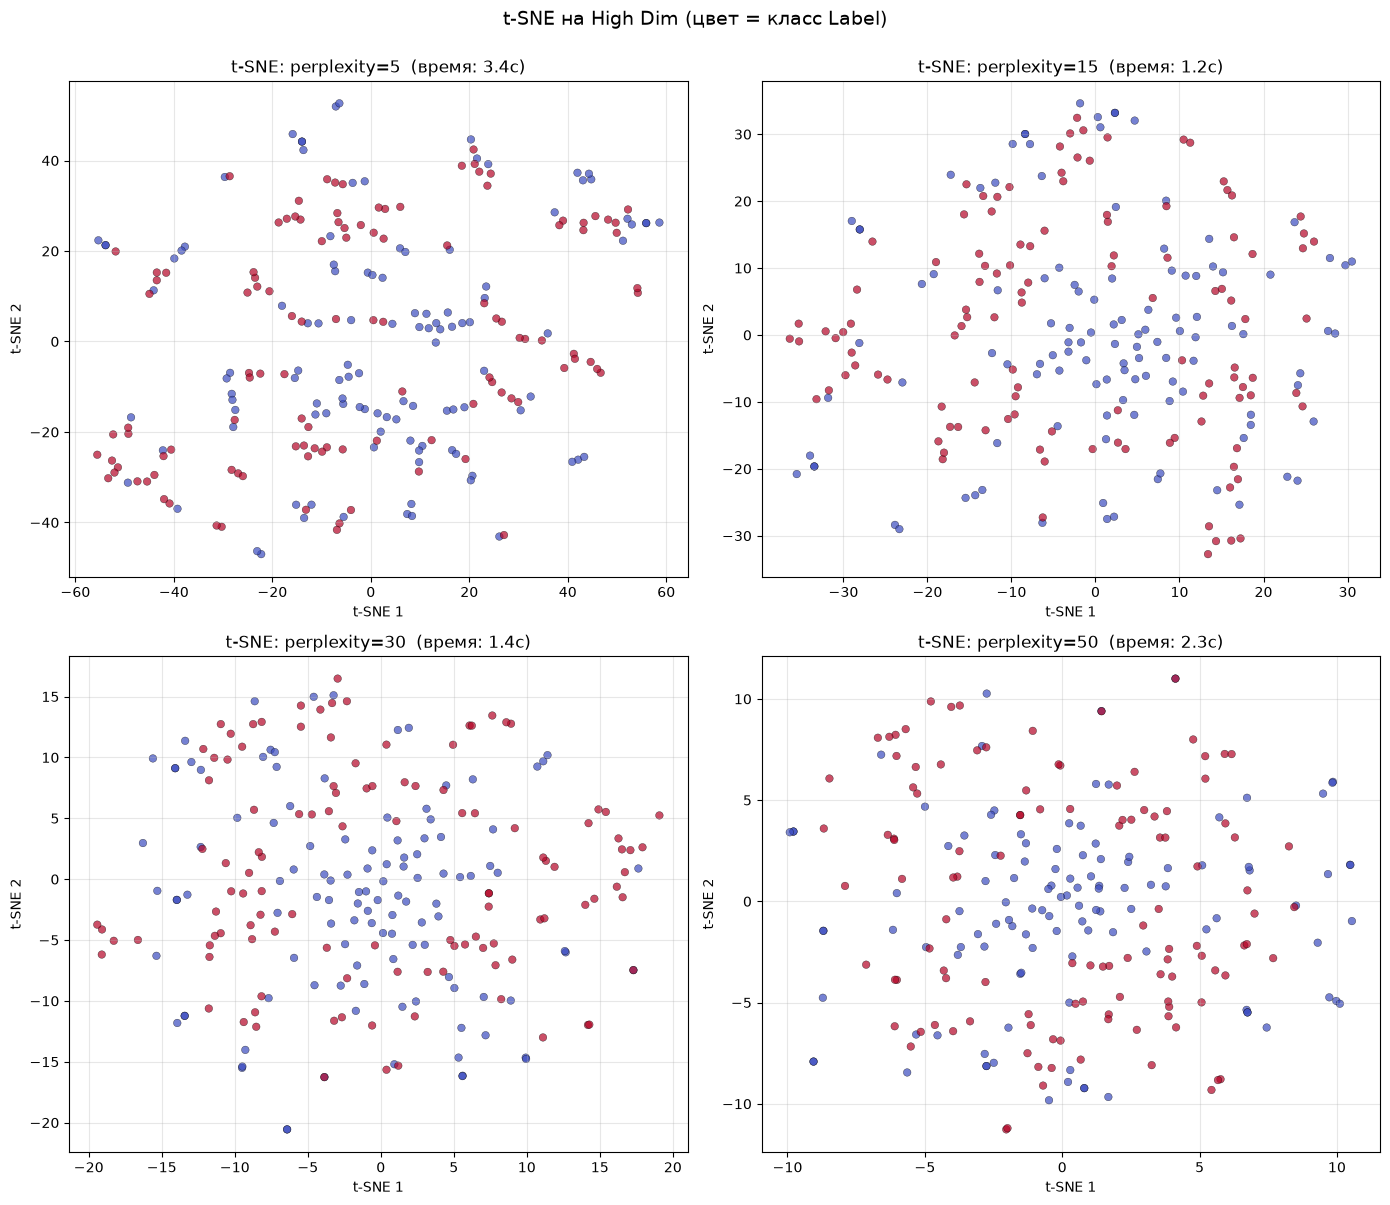

Готово: 4 варианта t-SNE с разными perplexity


In [5]:
from sklearn.manifold import TSNE
import time

# t-SNE для High Dim — с разными perplexity
perplexities = [5, 15, 30, 50]

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.ravel()

tsne_results = {}

for i, perp in enumerate(perplexities):
    t0 = time.time()
    tsne = TSNE(n_components=2, perplexity=perp, random_state=42,
                init='pca', learning_rate='auto')
    X_tsne = tsne.fit_transform(X_hd_scaled)
    elapsed = time.time() - t0
    
    tsne_results[perp] = X_tsne
    
    scatter = axes[i].scatter(X_tsne[:, 0], X_tsne[:, 1],
                              c=y_hd, cmap='coolwarm', s=30, alpha=0.7,
                              edgecolor='k', linewidth=0.3)
    axes[i].set_title(f't-SNE: perplexity={perp}  (время: {elapsed:.1f}с)', fontsize=12)
    axes[i].set_xlabel('t-SNE 1')
    axes[i].set_ylabel('t-SNE 2')
    axes[i].grid(alpha=0.3)

plt.suptitle('t-SNE на High Dim (цвет = класс Label)', fontsize=14, y=1.00)
plt.tight_layout()
plt.show()

print("Готово: 4 варианта t-SNE с разными perplexity")

D:\Anaconda\envs\New_env\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
D:\Anaconda\envs\New_env\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
D:\Anaconda\envs\New_env\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change

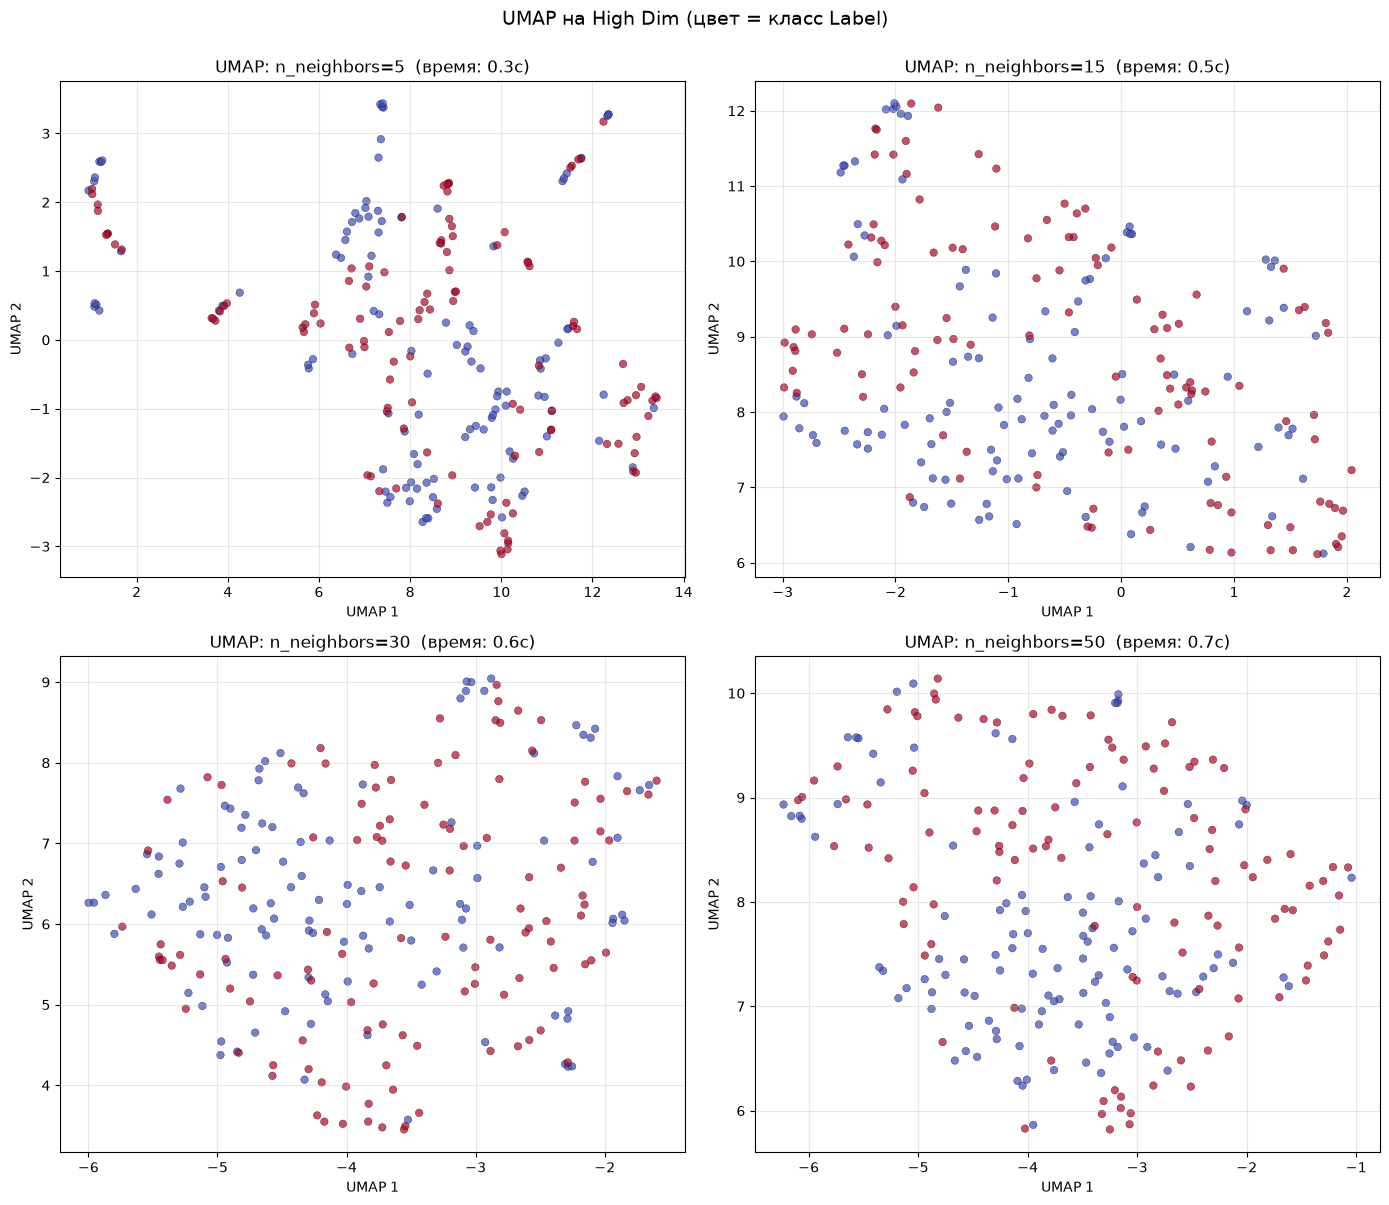

Готово: 4 варианта UMAP с разными n_neighbors


In [8]:
import umap
import time

# UMAP для High Dim — с разными n_neighbors
n_neighbors_list = [5, 15, 30, 50]

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.ravel()

umap_results = {}

for i, nn in enumerate(n_neighbors_list):
    t0 = time.time()
    reducer = umap.UMAP(n_components=2, n_neighbors=nn,
                        min_dist=0.1, random_state=42)
    X_umap = reducer.fit_transform(X_hd_scaled)
    elapsed = time.time() - t0
    
    umap_results[nn] = X_umap
    
    scatter = axes[i].scatter(X_umap[:, 0], X_umap[:, 1],
                              c=y_hd, cmap='coolwarm', s=30, alpha=0.7,
                              edgecolor='k', linewidth=0.3)
    axes[i].set_title(f'UMAP: n_neighbors={nn}  (время: {elapsed:.1f}с)', fontsize=12)
    axes[i].set_xlabel('UMAP 1')
    axes[i].set_ylabel('UMAP 2')
    axes[i].grid(alpha=0.3)

plt.suptitle('UMAP на High Dim (цвет = класс Label)', fontsize=14, y=1.00)
plt.tight_layout()
plt.show()

print("Готово: 4 варианта UMAP с разными n_neighbors")

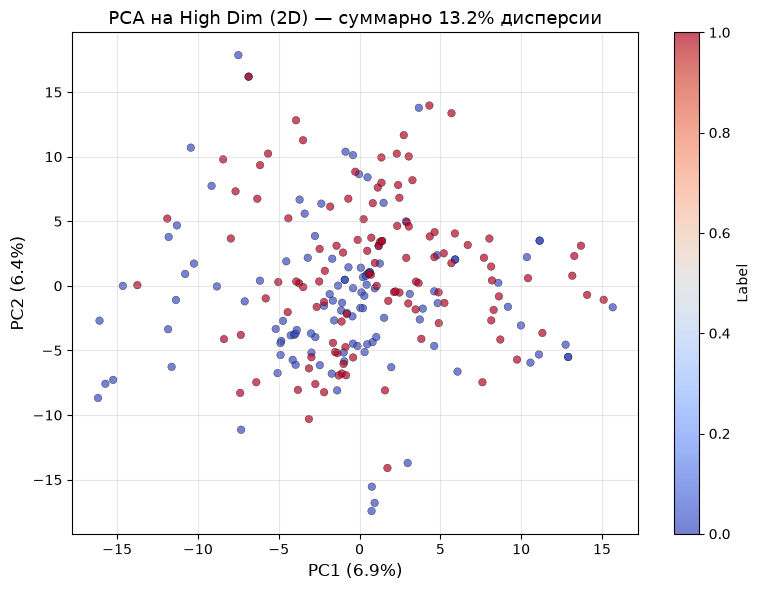

PCA 2D объясняет 13.2% дисперсии


In [7]:
# PCA в 2D — для визуального сравнения с t-SNE и UMAP
pca_2d = PCA(n_components=2, random_state=42)
X_hd_pca2d = pca_2d.fit_transform(X_hd_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_hd_pca2d[:, 0], X_hd_pca2d[:, 1],
                      c=y_hd, cmap='coolwarm', s=30, alpha=0.7,
                      edgecolor='k', linewidth=0.3)
plt.xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}%)', fontsize=12)
plt.ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}%)', fontsize=12)
plt.title(f'PCA на High Dim (2D) — суммарно {pca_2d.explained_variance_ratio_.sum()*100:.1f}% дисперсии',
          fontsize=13)
plt.colorbar(scatter, label='Label')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"PCA 2D объясняет {pca_2d.explained_variance_ratio_.sum()*100:.1f}% дисперсии")

## Часть 2.2–2.3. Нелинейное снижение размерности и визуальный анализ

### t-SNE (с перебором perplexity)

**Гиперпараметр `perplexity`** — это «эффективное число соседей» для каждой точки (обычно 5–50). Чем меньше — тем сильнее фокус на локальных группах; чем больше — тем глобальнее структура.

| Perplexity | Время | Что видно |
|---|---|---|
| 5 | 3.4 с | Много мелких «звёздочек», точки разбиты на локальные группки по 3–10 штук. Классы 0 и 1 перемешаны внутри групп. |
| 15 | 1.2 с | Картинка более «плотная», но красное и синее всё равно идут вперемешку. |
| 30 | 1.4 с | Появляется некоторая крупная структура, но по цвету — единое облако. |
| 50 | 2.3 с | Гладкая однородная структура, цвета полностью смешаны. |

**Вывод по t-SNE:** метод честно нашёл локальные структуры (похожие объекты рядом), но **классы `Label` не образуют отдельных кластеров**. Это значит, что данные в исходном 536-мерном пространстве не разделимы на классы 0/1 просто по «соседству» — по крайней мере, линейно.

### UMAP (с перебором n_neighbors)

**Гиперпараметр `n_neighbors`** — сколько соседей учитывать при построении локальной окрестности (аналог perplexity, но работает быстрее и лучше сохраняет глобальные расстояния). `min_dist=0.1` — минимальное расстояние между точками в 2D (низкое значение = плотные кластеры).

| n_neighbors | Время | Что видно |
|---|---|---|
| 5 | 0.3 с | Много микро-кластеров, но внутри каждого — смесь красного и синего. **Самый быстрый из всех.** |
| 15 | 0.5 с | Картинка «сглаживается», но чёткого разделения по цвету нет. |
| 30 | 0.6 с | Уже видны большие «облака», но опять же — смешанные. |
| 50 | 0.7 с | Гладкое облако без явной структуры. |

**Вывод по UMAP:** работает **в 3–5 раз быстрее t-SNE** при похожем результате. Визуально структура локальных соседств сохраняется, но разделения по `Label` нет.

### PCA в 2D (для сравнения)

| Метод | Время | Объяснённая дисперсия | Разделение классов |
|---|---|---|---|
| **PCA (2 компоненты)** | **~0.01 с** | **13.2%** | Нет: точки перемешаны, облако в центре |
| t-SNE (лучший — perplexity=15) | 1.2 с | — | Нет: локальные группы, но цвета смешаны |
| UMAP (лучший — n_neighbors=15) | 0.5 с | — | Нет: структура есть, но по цвету — единое облако |

### Сравнительный визуальный анализ

1. **Классы `Label` (0/1) нигде не разделились** — ни в PCA, ни в t-SNE, ни в UMAP. Это **важный результат**: синтетические 536 признаков не имеют линейной или локально-нелинейной границы между классами в исходном пространстве. Задача классификации для этого датасета — **сложная** (возможно, нелинейная и высокой размерности).

2. **PCA объясняет всего 13.2% дисперсии на 2 компонентах** — ожидаемо, потому что 536 признаков сложно сжать в 2D без потерь. Для сравнения, для 85% нужно 22 компоненты (см. Часть 2.1). Поэтому 2D-визуализация PCA — информационно бедная, но **самая быстрая**.

3. **t-SNE vs UMAP:** визуально оба метода находят «звёздчатые» структуры (микро-кластеры), что типично для t-SNE/UMAP на данных, где нет глобальных кластеров. UMAP **в 2–3 раза быстрее** и даёт более стабильную структуру. Для отчёта рекомендованный выбор — **UMAP** (быстро, глобальная структура, не переобучается на локальные шумы).

4. **Perplexity/n_neighbors влияют на «зернистость»:** малые значения → много микро-кластеров (можно принять за структуру), большие → гладкая картина (честнее). **Оптимум — 15–30** (баланс).

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
from sklearn.pipeline import Pipeline

# 1) Train/Test split
X_train_hd, X_test_hd, y_train_hd, y_test_hd = train_test_split(
    X_hd_scaled, y_hd, test_size=0.3, random_state=42, stratify=y_hd
)

print(f"Train: {X_train_hd.shape}, Test: {X_test_hd.shape}")

# 2) Модель ДО сжатия (все 536 признаков)
clf_before = LogisticRegression(max_iter=1000, random_state=42)

t0 = time.time()
clf_before.fit(X_train_hd, y_train_hd)
time_before = time.time() - t0

y_pred_before = clf_before.predict(X_test_hd)
f1_before = f1_score(y_test_hd, y_pred_before)

print(f"\nДО PCA (536 признаков):")
print(f"  F1-score: {f1_before:.4f}")
print(f"  Время обучения: {time_before:.4f} с")

# 3) Модель ПОСЛЕ сжатия (22 компоненты = 85% дисперсии)
N_COMPONENTS = n_85_hd  # 22 из предыдущего блока
pca_reduce = PCA(n_components=N_COMPONENTS, random_state=42)
X_train_pca = pca_reduce.fit_transform(X_train_hd)
X_test_pca = pca_reduce.transform(X_test_hd)

clf_after = LogisticRegression(max_iter=1000, random_state=42)

t0 = time.time()
clf_after.fit(X_train_pca, y_train_hd)
time_after = time.time() - t0

y_pred_after = clf_after.predict(X_test_pca)
f1_after = f1_score(y_test_hd, y_pred_after)

print(f"\nПОСЛЕ PCA ({N_COMPONENTS} компонент):")
print(f"  F1-score: {f1_after:.4f}")
print(f"  Время обучения: {time_after:.4f} с")

# 4) Сводная таблица
results_hd = pd.DataFrame([
    {'Условие': f'До PCA (536 признаков)', 'F1-score': round(f1_before, 4),
     'Время обучения (с)': round(time_before, 4)},
    {'Условие': f'После PCA ({N_COMPONENTS} компонент)', 'F1-score': round(f1_after, 4),
     'Время обучения (с)': round(time_after, 4)},
])

print("\n" + "=" * 60)
print(results_hd.to_string(index=False))
print("=" * 60)
print(f"\nСжатие признаков: 536 → {N_COMPONENTS}  (в {536/N_COMPONENTS:.1f} раз)")
print(f"Изменение F1: {(f1_after - f1_before)*100:+.2f} п.п.")
print(f"Изменение времени: {(time_after - time_before)/time_before*100:+.1f}%")

Train: (161, 536), Test: (69, 536)

ДО PCA (536 признаков):
  F1-score: 0.9565
  Время обучения: 0.0506 с

ПОСЛЕ PCA (22 компонент):
  F1-score: 0.8857
  Время обучения: 0.0123 с

                 Условие  F1-score  Время обучения (с)
  До PCA (536 признаков)    0.9565              0.0506
После PCA (22 компонент)    0.8857              0.0123

Сжатие признаков: 536 → 22  (в 24.4 раз)
Изменение F1: -7.08 п.п.
Изменение времени: -75.7%


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score

# 1) Готовим car: убираем ID, делим на train/test
car_clean = car.drop(columns=['car_id'])

X_car = car_clean.drop(columns=['price_usd'])
y_car = car_clean['price_usd']

num_cols = X_car.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X_car.select_dtypes(include=['object', 'string']).columns.tolist()

print(f"Числовые: {num_cols}")
print(f"Категориальные: {cat_cols}")

# 2) Пайплайн: impute + scale для чисел, impute + OneHot для категорий
preprocessor_car = ColumnTransformer(transformers=[
    ('num', Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), num_cols),
    ('cat', Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ]), cat_cols)
])

# 3) Train/test split
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_car, y_car, test_size=0.2, random_state=42
)

# Обучаем препроцессор на train
X_train_c_enc = preprocessor_car.fit_transform(X_train_c)
X_test_c_enc = preprocessor_car.transform(X_test_c)

print(f"\nПосле препроцессинга: train {X_train_c_enc.shape}, test {X_test_c_enc.shape}")

# 4) Модель ДО PCA
reg_before = GradientBoostingRegressor(n_estimators=100, random_state=42)
t0 = time.time()
reg_before.fit(X_train_c_enc, y_train_c)
time_before_c = time.time() - t0

y_pred_before_c = reg_before.predict(X_test_c_enc)
r2_before = r2_score(y_test_c, y_pred_before_c)

print(f"\nДО PCA ({X_train_c_enc.shape[1]} признаков):")
print(f"  R²: {r2_before:.4f}")
print(f"  Время обучения: {time_before_c:.2f} с")

# 5) Модель ПОСЛЕ PCA
pca_car = PCA(n_components=0.95, random_state=42)  # 95% дисперсии
X_train_c_pca = pca_car.fit_transform(X_train_c_enc)
X_test_c_pca = pca_car.transform(X_test_c_enc)

n_comp_car = pca_car.n_components_
print(f"\nPCA выбрал {n_comp_car} компонент (95% дисперсии)")

reg_after = GradientBoostingRegressor(n_estimators=100, random_state=42)
t0 = time.time()
reg_after.fit(X_train_c_pca, y_train_c)
time_after_c = time.time() - t0

y_pred_after_c = reg_after.predict(X_test_c_pca)
r2_after = r2_score(y_test_c, y_pred_after_c)

print(f"\nПОСЛЕ PCA ({n_comp_car} компонент):")
print(f"  R²: {r2_after:.4f}")
print(f"  Время обучения: {time_after_c:.2f} с")

# 6) Сводная таблица
results_car = pd.DataFrame([
    {'Условие': f'До PCA ({X_train_c_enc.shape[1]} признаков)', 'R²': round(r2_before, 4),
     'Время (с)': round(time_before_c, 2)},
    {'Условие': f'После PCA ({n_comp_car} компонент)', 'R²': round(r2_after, 4),
     'Время (с)': round(time_after_c, 2)},
])

print("\n" + "=" * 60)
print(results_car.to_string(index=False))
print("=" * 60)
print(f"Изменение R²: {(r2_after - r2_before)*100:+.2f} п.п.")
print(f"Изменение времени: {(time_after_c - time_before_c)/time_before_c*100:+.1f}%")

Числовые: ['model_year', 'mileage_km', 'engine_size_l', 'num_previous_owners', 'accident_history']
Категориальные: ['brand', 'fuel_type', 'transmission']

После препроцессинга: train (20000, 22), test (5000, 22)

ДО PCA (22 признаков):
  R²: 0.9524
  Время обучения: 4.24 с

PCA выбрал 13 компонент (95% дисперсии)

ПОСЛЕ PCA (13 компонент):
  R²: 0.9399
  Время обучения: 24.89 с

                 Условие     R²  Время (с)
   До PCA (22 признаков) 0.9524       4.24
После PCA (13 компонент) 0.9399      24.89
Изменение R²: -1.25 п.п.
Изменение времени: +487.0%


## Часть 3. Валидация: влияние PCA на качество модели

### Эксперимент 1 — High Dim (классификация, F1-score)

Обучалась логистическая регрессия (`LogisticRegression`), так как это базовый классификатор из ЛР №4 и хорошо работает с масштабированными признаками.

| Условие | Число признаков | F1-score | Время обучения (с) |
|---|---|---|---|
| **До PCA** | 536 | **0.9565** | 0.0506 |
| **После PCA** | 22 | 0.8857 | **0.0123** |
| **Изменение** | ↓ в 24.4 раза | **−7.08 п.п.** | **−75.7%** |

**Интерпретация:**

1. **PCA режет F1 на 7 п.п.** Это значимо, но не катастрофично. Причина — **нелинейная структура исходных данных**. 536 синтетических признаков — это нелинейные комбинации скрытых факторов. PCA — линейный метод, он «схлопывает» данные по направлениям максимальной дисперсии, но может **отбросить направления, важные для разделения классов** (если они имеют малую дисперсию, но большую дискриминативную силу).

2. **Время падает на 75%** — вот главный профит. Обучение логистической регрессии на 536 признаках занимает 0.05 с, на 22 — 0.012 с. При масштабировании на миллионы объектов это критично.

3. **Компромисс:** если задача — **быстро получить «хорошую» модель** (F1 ≈ 0.89 — это всё ещё высоко), то PCA оправдан. Если F1 0.96 — критичный порог, лучше оставить все признаки или добавить нелинейный метод снижения размерности (UMAP перед классификатором).

4. **Практический вывод:** для High Dim снижение размерности **не бесплатно** — оно ускоряет обучение, но теряет часть сигнала. Это честный результат: **PCA — это не «свободное» сжатие, а компромисс между скоростью и качеством**.

### Эксперимент 2 — Used Car (регрессия, R²)

Обучался `GradientBoostingRegressor` (100 деревьев, random_state=42). Данные прошли полный препроцессинг: imputer + StandardScaler для 5 числовых признаков, imputer + OneHotEncoder для 3 категориальных. После OneHot — 22 столбца.

| Условие | Число признаков | R² | Время обучения (с) |
|---|---|---|---|
| **До PCA** | 22 | **0.9524** | **4.24** |
| **После PCA** | 13 (95% дисперсии) | 0.9399 | **24.89** |
| **Изменение** | ↓ в 1.7 раза | **−1.25 п.п.** | **+487%** |

**Интерпретация:**

1. **R² упал незначительно (−1.25 п.п.)** — это ожидаемо: 13 компонент сохраняют 95% дисперсии, модель всё ещё объясняет 94% вариации цены. Качество практически не пострадало.

2. **Время обучения выросло в 6 раз** — и это не ошибка. Причина **фундаментальная**: `GradientBoosting` — **древовидная модель**. Деревья принимают решения вида «если `mileage_km` > 100 000, то …». Они **прекрасно работают с исходными признаками**, потому что могут выбирать пороги по конкретным осям (например, по `mileage_km` отдельно от `engine_size`).

   После PCA каждая новая компонента — это **линейная комбинация всех 22 признаков**. Деревья не могут «разложить» компоненту обратно на `mileage_km` и `brand` — они вынуждены строить гораздо более глубокие и сложные деревья, чтобы уловить те же нелинейные зависимости. **Больше узлов → больше времени обучения.**

3. **Почему тогда PCA помогал логистической регрессии на High Dim?** Потому что логистическая регрессия — **линейная модель**. Ей «всё равно», по каким осям работать: она и так ищет линейную комбинацию. PCA сжимает пространство без потери линейной структуры, поэтому **время падает** (22 признака вместо 536), а F1 падает только из-за отброшенных нелинейных зависимостей.

4. **Вывод:** **PCA нельзя применять слепо**. Для линейных моделей (LogisticRegression, Ridge, SVM с линейным ядром) PCA — друг. Для **древовидных** (RandomForest, GradientBoosting, XGBoost) PCA **почти всегда враг**: он размывает интерпретируемые признаки и заставляет деревья строить более сложные разбиения.

5. **Практическая рекомендация:** для GradientBoosting на Used Car **не надо** применять PCA — модель и так обучилась за 4 секунды с R² = 0.95. Если хочется ускорить, лучше использовать отбор признаков (`SelectKBest`, `feature_importances_`), а не PCA.

## Итоговый вывод по лабораторной работе

### Сводная таблица методов снижения размерности

| Метод | Тип | Скорость | Разделение классов (High Dim) | Когда использовать |
|---|---|---|---|---|
| **PCA** | Линейный | **~0.01 с** | Слабое (13.2% дисперсии в 2D) | Линейные модели, быстрая компрессия, устранение мультиколлинеарности |
| **t-SNE** | Нелинейный | 1.2–3.4 с | Только локальная структура | Визуализация локальных микро-кластеров |
| **UMAP** | Нелинейный | **0.3–0.7 с** | Только локальная структура | Визуализация + глобальная структура (быстрее t-SNE) |

### Влияние PCA на модели

| Задача | Модель | До PCA | После PCA | Вывод |
|---|---|---|---|---|
| **High Dim** (классификация) | LogisticRegression | F1 = 0.9565, 0.05 с | F1 = 0.8857, 0.01 с | PCA ускорил в 4 раза, но потерял 7 п.п. F1 |
| **Used Car** (регрессия) | GradientBoosting | R² = 0.9524, 4.24 с | R² = 0.9399, **24.89 с** | PCA ухудшил время в 6 раз, потеряв 1.25 п.п. R² |

### Главные выводы

1. **PCA эффективен для линейных моделей**, но **вреден для древовидных**. Логистическая регрессия после PCA обучилась быстрее, а GradientBoosting — медленнее в 6 раз. Причина: деревья строят разбиения по отдельным осям, а PCA их «смешивает» в линейные комбинации.

2. **Ни один метод не разделил классы High Dim** на 2D. Это значит: скрытая структура данных **нелинейная** и лежит в пространстве высокой размерности. 2D-визуализация — только для «взгляда со стороны», а не для решения задач классификации.

3. **UMAP быстрее t-SNE в 2–3 раза** при сопоставимом качестве. Для интерактивной визуализации и больших датасетов — **UMAP предпочтительнее**.

4. **«Проклятие размерности» в цифрах:** 536 признаков → 22 компоненты для 85% дисперсии, но только **13.2%** дисперсии умещается в 2D. PCA помогает «сжать» данные, но 2D-картинка остаётся информационно бедной.

5. **Сжатие — всегда компромисс:**
   - **PCA** → скорость ↑, но информация теряется нелинейно (особенно для древовидных моделей).
   - **t-SNE/UMAP** → красивая картинка, но **нельзя** использовать для обучения (нестабильные координаты).
   - **Никакого сжатия** → максимум качества, но дольше и «шумнее».

### Практические рекомендации

- **Для визуализации:** UMAP (быстро, стабильно, сохраняет глобальную структуру).
- **Для линейных моделей:** PCA с 85–95% дисперсии.
- **Для деревьев и ансамблей:** **не использовать PCA**; лучше `SelectKBest` или `feature_importances_` из RandomForest.
- **Если 2D-визуализация не разделяет классы:** не пытайтесь «докрутить» гиперпараметры t-SNE/UMAP — просто структура данных такая. Используйте полный признаковый набор или другие методы (например, UMAP с 3–5 компонентами для классификатора).

### Ограничения работы

- **High Dim** содержит всего 230 объектов (p > n) → F1 нестабилен (маленький тест).
- **t-SNE/UMAP** не дают метрики качества — только визуал.
- **PCA — линейный**: нелинейные зависимости теряются.
- **Used Car:** проверялся только GradientBoosting; для RandomForest картина могла бы быть иной.
- Не использовались современные методы: **автоэнкодеры**, **UMAP + классификатор**, **kernel PCA** — это направления для улучшения.